In [12]:
%pip install numpy pandas scikit-learn matplotlib joblib requests


# Import Libraries

In [13]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

In [33]:



from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, ParameterSampler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

seed = 42
rul_cap = 125
checkpoint_ruls = (0, 25, 50, 75, 100, 125)


np.random.seed(seed)
print('Setup complete. Seed:', seed)


Setup complete. Seed: 42


In [15]:
train_file = 'train_FD001.txt'
test_file = 'test_FD001.txt'
rul_file =  'RUL_FD001.txt'


In [16]:

columns = (
    ['unit_id', 'cycle', 'setting_1', 'setting_2', 'setting_3']
    + [f'sensor_{i}' for i in range(1, 22)]
)

sensor_columns = [f'sensor_{i}' for i in range(1, 22)]
setting_columns = ['setting_1', 'setting_2', 'setting_3']

# Load the Datasets

In [17]:

train_raw = pd.read_csv(train_file,sep=r'\s+',header=None,names=columns)

test_raw = pd.read_csv(test_file,sep=r'\s+',header=None,names=columns)

official_rul = pd.read_csv(rul_file,sep=r'\s+',header=None,names=['rul'])['rul']

# Data validation


In [19]:

def validate_raw_frame(frame, label):
    missing = [column for column in columns if column not in frame.columns]

    if missing:
        raise ValueError(f'{label} is missing columns: {missing}')

    if frame.empty or frame[columns].isna().any().any():
        raise ValueError(
            f'{label} contains no rows or missing required values'
        )

    if frame.duplicated(['unit_id', 'cycle']).any():
        raise ValueError(
            f'{label} contains duplicate engine/cycle rows'
        )

    if (frame['cycle'] < 1).any():
        raise ValueError(f'{label} has a non-positive cycle number')

validate_raw_frame(train_raw, 'Training data')
validate_raw_frame(test_raw, 'Test data')

if test_raw.unit_id.nunique() != len(official_rul):
    raise ValueError(
        'Test engine count and official RUL label count do not match'
    )

if (official_rul < 0).any():
    raise ValueError('Official RUL labels must be non-negative')

In [20]:

print(f'Train: {len(train_raw):,} rows, '
    f'{train_raw.unit_id.nunique()} engines'
)

print(
    f'Test: {len(test_raw):,} rows, '
    f'{test_raw.unit_id.nunique()} engines'
)

print('Columns per observation:', len(columns))

display(train_raw.head())


Train: 20,631 rows, 100 engines
Test: 13,096 rows, 100 engines
Columns per observation: 26


,unit_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


,quantity,value
0,training rows,20631
1,training engines,100
2,test rows,13096
3,test engines,100
4,sensor measurements,21
5,setting measurements,3


Training trajectory length quantiles:


,cycles
0.00,128.00
0.25,177.00
0.50,199.00
0.75,229.25
1.00,362.00


Official test RUL quantiles (uncapped):


,cycles
0.00,7.00
0.25,32.75
0.50,86.00
0.75,112.25
1.00,145.00


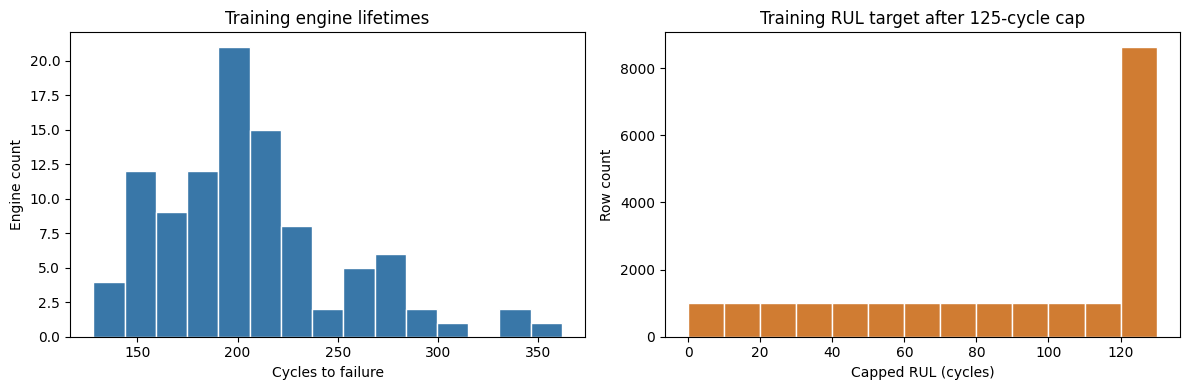

In [24]:

# calculate engine trajectory lengths
train_length = train_raw.groupby('unit_id')['cycle'].max().rename('last_cycle')
test_length = test_raw.groupby('unit_id')['cycle'].max().rename('last_cycle')


# calculate training remaining useful life (rul)
uncapped_train_rul = (
    train_raw.groupby('unit_id')['cycle'].transform('max')
    - train_raw['cycle']
)

capped_train_rul = uncapped_train_rul.clip(upper=rul_cap)


# create dataset summary
summary = pd.DataFrame({
    'quantity': [
        'training rows',
        'training engines',
        'test rows',
        'test engines',
        'sensor measurements',
        'setting measurements'
    ],
    'value': [
        len(train_raw),
        train_raw.unit_id.nunique(),
        len(test_raw),
        test_raw.unit_id.nunique(),
        len(sensor_columns),
        len(setting_columns)
    ]
})

display(summary)


# display training trajectory length statistics
print('Training trajectory length quantiles:')

display(
    train_length.quantile([0, 0.25, 0.5, 0.75, 1])
    .rename('cycles')
    .to_frame()
)


# display official test rul statistics
print('Official test RUL quantiles (uncapped):')

display(
    official_rul.quantile([0, 0.25, 0.5, 0.75, 1])
    .rename('cycles')
    .to_frame()
)


# visualize training engine lifetimes and rul distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))


# plot training engine lifetimes
axes[0].hist(
    train_length,
    bins=15,
    color='#3977a8',
    edgecolor='white'
)

axes[0].set(
    title='Training engine lifetimes',
    xlabel='Cycles to failure',
    ylabel='Engine count'
)


# plot capped training rul distribution
axes[1].hist(
    capped_train_rul,
    bins=np.arange(0, rul_cap + 11, 10),
    color='#d07c32',
    edgecolor='white'
)

axes[1].set(
    title=f'Training RUL target after {rul_cap}-cycle cap',
    xlabel='Capped RUL (cycles)',
    ylabel='Row count'
)


# adjust layout and display plots
fig.tight_layout()
plt.show()


Training sensor standard deviations (smallest first):


,standard_deviation
sensor_19,0.000000e+00
sensor_18,0.000000e+00
sensor_16,1.556432e-14
sensor_10,4.660829e-13
sensor_5,3.394700e-12
sensor_1,6.537152e-11
sensor_6,1.388985e-03
sensor_15,3.750504e-02
sensor_8,7.098548e-02
sensor_13,7.191892e-02


Sensors with effectively no variation: ['sensor_19', 'sensor_18', 'sensor_16', 'sensor_10', 'sensor_5', 'sensor_1']
Operating-setting standard deviations:


,standard_deviation
setting_1,0.002187
setting_2,0.000293
setting_3,0.000000


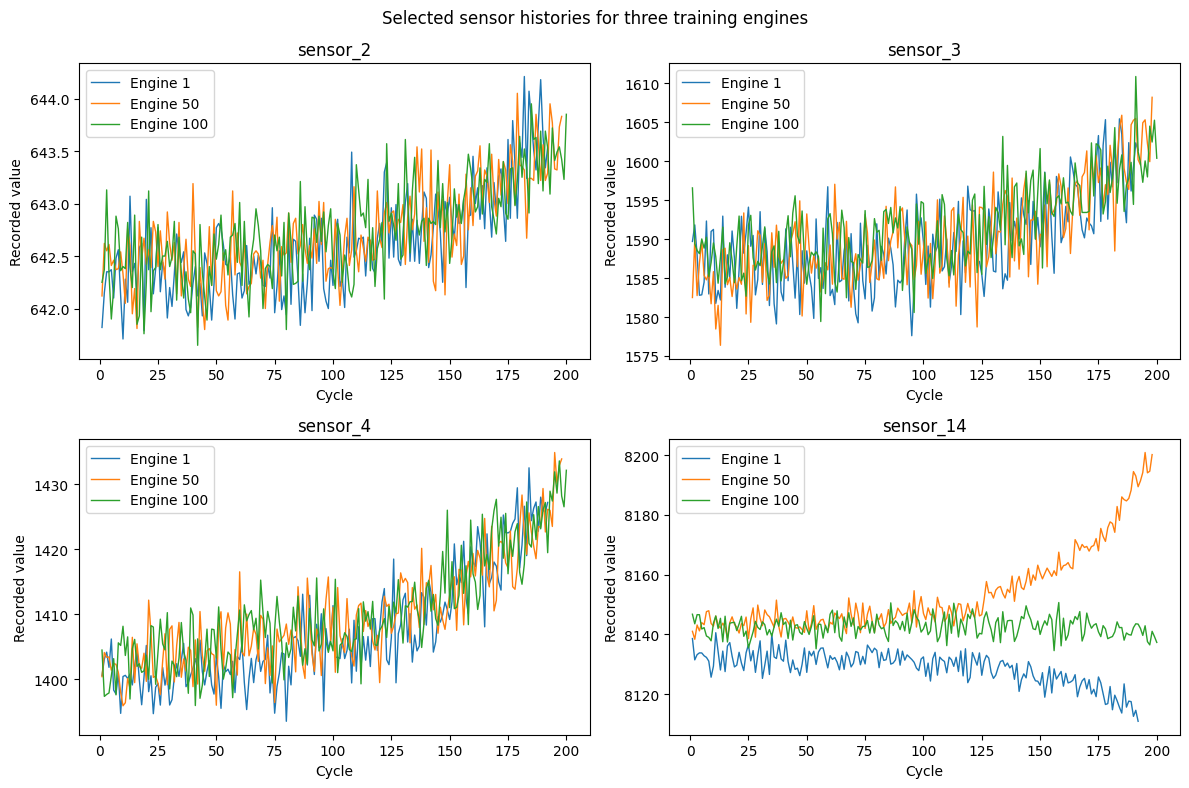

In [26]:

# calculate sensor standard deviations
sensor_spread = train_raw[sensor_columns].std().sort_values()

constant_sensors = sensor_spread[sensor_spread < 1e-8].index.tolist()
# display sensor variability
print('Training sensor standard deviations (smallest first):')

display(sensor_spread.to_frame('standard_deviation').head(10))

print('Sensors with effectively no variation:',constant_sensors or 'none')

# display operating-setting standard deviations
print('Operating-setting standard deviations:')

display(train_raw[setting_columns].std().to_frame('standard_deviation'))

# select example engines and sensors
example_units = [1, 50, 100]
example_sensors = ['sensor_2','sensor_3','sensor_4','sensor_14']


# visualize sensor trajectories
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, sensor in zip(axes.flat, example_sensors):
    for unit_id in example_units:
        trajectory = train_raw.loc[
            train_raw.unit_id == unit_id
        ]

        ax.plot(
            trajectory.cycle,
            trajectory[sensor],
            label=f'Engine {unit_id}',
            linewidth=1
        )

    ax.set(
        title=sensor,
        xlabel='Cycle',
        ylabel='Recorded value'
    )

    ax.legend()
# adjust layout and display plots
fig.suptitle('Selected sensor histories for three training engines')
fig.tight_layout()
plt.show()


In [27]:

# add remaining useful life (rul) target to training data
def add_training_target(frame, cap=rul_cap):
    result = frame.copy()

    last_cycle = result.groupby('unit_id')['cycle'].transform('max')

    result['rul'] = (
        last_cycle - result['cycle']
    ).clip(upper=cap)

    return result


# engineer time-series features
def engineer_features(frame):
    validate_raw_frame(frame, 'Feature input')

    result = frame.sort_values(
        ['unit_id', 'cycle']
    ).copy()

    result['cycles_from_start'] = result['cycle'] - 1

    engineered = {}

    for sensor in sensor_columns:

        grouped = result.groupby(
            'unit_id',
            sort=False
        )[sensor]

        # calculate first-order differences
        engineered[f'{sensor}_diff1'] = (
            grouped.diff().fillna(0.0)
        )

        # calculate rolling means
        for window in (5, 10, 20):

            engineered[f'{sensor}_mean_{window}'] = grouped.transform(
                lambda values, width=window:
                    values.rolling(
                        width,
                        min_periods=1
                    ).mean()
            )

        # calculate rolling standard deviations
        for window in (5, 10):

            engineered[f'{sensor}_std_{window}'] = grouped.transform(
                lambda values, width=window:
                    values.rolling(
                        width,
                        min_periods=2
                    ).std()
            ).fillna(0.0)

    # combine original and engineered features
    result = pd.concat(
        [
            result,
            pd.DataFrame(engineered, index=result.index)
        ],
        axis=1
    )

    return result.replace(
        [np.inf, -np.inf],
        np.nan
    )


# prepare training and test datasets
train = engineer_features(
    add_training_target(train_raw)
)

test = engineer_features(test_raw)


# identify model input features
feature_columns = [
    column
    for column in train.columns
    if column not in ('unit_id', 'rul')
]


# display feature information
print(
    f'{len(feature_columns)} features created '
    f'from {len(columns) - 1} raw predictors.'
)


# display sample engineered features
display(
    train[
        [
            'unit_id',
            'cycle',
            'rul',
            'sensor_2',
            'sensor_2_diff1',
            'sensor_2_mean_5',
            'sensor_2_std_5'
        ]
    ].head(8)
)


152 features created from 25 raw predictors.


,unit_id,cycle,rul,sensor_2,sensor_2_diff1,sensor_2_mean_5,sensor_2_std_5
0,1,1,125,641.82,0.00,641.820000,0.000000
1,1,2,125,642.15,0.33,641.985000,0.233345
2,1,3,125,642.35,0.20,642.106667,0.267644
3,1,4,125,642.35,0.00,642.167500,0.250117
4,1,5,125,642.37,0.02,642.208000,0.234776
5,1,6,125,642.10,-0.27,642.264000,0.128374
6,1,7,125,642.48,0.38,642.330000,0.139463
7,1,8,125,642.56,0.08,642.372000,0.174270


In [34]:

# split engine ids into training and validation groups
engine_ids = np.sort(train.unit_id.unique())

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=seed
)

train_engine_pos, validation_engine_pos = next(
    splitter.split(engine_ids, groups=engine_ids)
)

fit_engine_ids = engine_ids[train_engine_pos]
validation_engine_ids = engine_ids[validation_engine_pos]


# create validation checkpoints from censored engine trajectories
def make_censored_anchors(
    feature_frame,
    selected_engine_ids,
    checkpoints=checkpoint_ruls
):
    """Select rows at fixed remaining-life checkpoints from held-out run-to-failure engines."""

    rows = []

    selected = feature_frame.loc[
        feature_frame.unit_id.isin(selected_engine_ids)
    ]

    for unit_id, trajectory in selected.groupby(
        'unit_id',
        sort=True
    ):

        final_cycle = int(trajectory.cycle.max())

        for requested_rul in checkpoints:

            if requested_rul > final_cycle - 1:
                continue

            cutoff_cycle = final_cycle - requested_rul

            matching = trajectory.loc[
                trajectory.cycle == cutoff_cycle
            ]

            if matching.empty:
                raise ValueError(
                    f'No cycle {cutoff_cycle} for engine {unit_id}'
                )

            rows.append(matching.index[0])

    anchors = feature_frame.loc[rows].sort_values(
        ['unit_id', 'cycle']
    ).copy()

    if anchors.empty:
        raise ValueError(
            'No validation checkpoints were created'
        )

    return anchors


# generate validation checkpoints
validation_anchors = make_censored_anchors(
    train,
    validation_engine_ids
)


# display training and validation split information
print(
    f'Tuning engines: {len(fit_engine_ids)}; '
    f'untouched validation engines: {len(validation_engine_ids)}'
)

print(
    f'Validation checkpoints: {len(validation_anchors)} '
    f'({validation_anchors.unit_id.nunique()} engines)'
)


# display validation checkpoint distribution
display(
    validation_anchors.groupby('rul')
    .size()
    .rename('checkpoint_count')
    .to_frame()
)


Tuning engines: 80; untouched validation engines: 20
Validation checkpoints: 120 (20 engines)


,checkpoint_count
rul,
0,20
25,20
50,20
75,20
100,20
125,20


In [35]:

# define hyperparameter search space
parameter_space = {
    'learning_rate': [0.03, 0.06, 0.10],
    'max_iter': [150, 250, 350],
    'max_leaf_nodes': [7, 15, 31],
    'min_samples_leaf': [10, 20, 30],
    'l2_regularization': [0.0, 1.0, 5.0]
}

n_search_candidates = 8


# generate random parameter combinations
candidates = list(
    ParameterSampler(
        parameter_space,
        n_iter=n_search_candidates,
        random_state=seed
    )
)


# initialize grouped cross-validation
cv = GroupKFold(n_splits=4)

cv_rows = []

fit_rows = train.loc[
    train.unit_id.isin(fit_engine_ids)
]


# evaluate each hyperparameter candidate
for candidate_number, parameters in enumerate(
    candidates,
    start=1
):

    fold_mae = []

    for inner_train_pos, inner_valid_pos in cv.split(
        fit_engine_ids,
        groups=fit_engine_ids
    ):

        inner_train_ids = fit_engine_ids[inner_train_pos]
        inner_valid_ids = fit_engine_ids[inner_valid_pos]

        inner_train = fit_rows.loc[
            fit_rows.unit_id.isin(inner_train_ids)
        ]

        inner_anchors = make_censored_anchors(
            fit_rows,
            inner_valid_ids
        )

        # initialize and train model
        model = HistGradientBoostingRegressor(
            random_state=seed,
            **parameters
        )

        model.fit(
            inner_train[feature_columns],
            inner_train['rul']
        )

        # generate predictions and calculate mae
        inner_prediction = np.clip(
            model.predict(inner_anchors[feature_columns]),
            0,
            rul_cap
        )

        fold_mae.append(
            mean_absolute_error(
                inner_anchors['rul'],
                inner_prediction
            )
        )

    # store cross-validation results
    cv_rows.append({
        **parameters,
        'mean_cv_mae': float(np.mean(fold_mae)),
        'std_cv_mae': float(np.std(fold_mae))
    })

    print(
        f'Candidate {candidate_number}/{len(candidates)}: '
        f'mean grouped-cv mae={np.mean(fold_mae):.2f}'
    )


# rank hyperparameter search results
search_results = (
    pd.DataFrame(cv_rows)
    .sort_values('mean_cv_mae')
    .reset_index(drop=True)
)


# select the best hyperparameters
best_parameters = {
    key: search_results.loc[0, key]
    for key in parameter_space
}


# convert numpy scalar values to native python values
best_parameters = {
    key: value.item() if hasattr(value, 'item') else value
    for key, value in best_parameters.items()
}


# display best parameters and search results
print('Best parameters:', best_parameters)

display(search_results)


Candidate 1/8: mean grouped-cv mae=13.72
Candidate 2/8: mean grouped-cv mae=14.31
Candidate 3/8: mean grouped-cv mae=13.56
Candidate 4/8: mean grouped-cv mae=13.53
Candidate 5/8: mean grouped-cv mae=13.55
Candidate 6/8: mean grouped-cv mae=14.01
Candidate 7/8: mean grouped-cv mae=13.61
Candidate 8/8: mean grouped-cv mae=13.71
Best parameters: {'learning_rate': 0.1, 'max_iter': 250, 'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'l2_regularization': 5.0}


,min_samples_leaf,max_leaf_nodes,max_iter,learning_rate,l2_regularization,mean_cv_mae,std_cv_mae
0,20,31,250,0.10,5.0,13.530987,0.559984
1,20,15,350,0.10,5.0,13.546986,0.850542
2,30,31,250,0.10,1.0,13.563764,0.524018
3,30,31,350,0.06,5.0,13.606851,0.710863
4,10,31,250,0.10,1.0,13.711586,0.330042
5,10,31,350,0.03,0.0,13.724182,0.451292
6,20,15,250,0.03,5.0,14.013254,0.627118
7,10,31,150,0.03,0.0,14.313546,0.321289


In [37]:

# calculate nasa asymmetric scoring metric
def nasa_asymmetric_score(actual, predicted):
    difference = (
        np.asarray(predicted) - np.asarray(actual)
    )

    exponent = np.where(
        difference < 0,
        -difference / 13.0,
        difference / 10.0
    )

    return float(
        np.mean(
            np.exp(np.clip(exponent, 0, 50)) - 1.0
        )
    )


# calculate regression evaluation metrics
def regression_metrics(actual, predicted):
    return {
        'mae': float(mean_absolute_error(actual, predicted)),
        'rmse': float(np.sqrt(mean_squared_error(actual, predicted))),
        'r2': float(r2_score(actual, predicted)),
        'nasa_score': nasa_asymmetric_score(actual, predicted)
    }


# prepare validation training and evaluation data
validation_train = train.loc[
    train.unit_id.isin(fit_engine_ids)
]

x_validation = validation_anchors[feature_columns]
y_validation = validation_anchors['rul']


# baseline model: predict median training rul
median_prediction = np.full(
    len(validation_anchors),
    validation_train['rul'].median()
)


# ridge regression baseline
# scaling is important because sensor columns have different ranges
ridge = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
    ('model', Ridge(alpha=10.0))
])

ridge.fit(
    validation_train[feature_columns],
    validation_train['rul']
)

ridge_prediction = np.clip(
    ridge.predict(x_validation),
    0,
    rul_cap
)


# tuned gradient boosting model
# train only on the outer training engines
tuned_model = HistGradientBoostingRegressor(
    random_state=seed,
    **best_parameters
)

tuned_model.fit(
    validation_train[feature_columns],
    validation_train['rul']
)

tuned_prediction = np.clip(
    tuned_model.predict(x_validation),
    0,
    rul_cap
)


# compare validation model performance
validation_comparison = pd.DataFrame([
    {
        'model': 'Median baseline',
        **regression_metrics(y_validation, median_prediction)
    },
    {
        'model': 'Ridge regression',
        **regression_metrics(y_validation, ridge_prediction)
    },
    {
        'model': 'Tuned HistGradientBoosting',
        **regression_metrics(y_validation, tuned_prediction)
    }
]).sort_values('mae').reset_index(drop=True)


# display and save validation results
display(validation_comparison)



,model,mae,rmse,r2,nasa_score
0,Tuned HistGradientBoosting,10.585223,15.145220,0.874170,4.664350
1,Ridge regression,12.423953,16.271332,0.854762,4.290712
2,Median baseline,47.833333,58.848676,-0.899794,5398.464025


In [38]:

# train the final model using the complete training dataset
final_model = HistGradientBoostingRegressor(
    random_state=seed,
    **best_parameters
)

final_model.fit(
    train[feature_columns],
    train['rul']
)


# identify the last observation for each test engine
test_last = test.loc[
    test.groupby('unit_id')['cycle'].idxmax()
].sort_values('unit_id')

test_ids = np.sort(test.unit_id.unique())


# validate test engine ordering and count
if not np.array_equal(
    test_last.unit_id.to_numpy(),
    test_ids
):
    raise ValueError(
        'Test predictions are not ordered consistently by engine ID'
    )

if len(test_last) != len(official_rul):
    raise ValueError(
        'Test checkpoint count and official RUL count differ'
    )


# prepare actual and predicted rul values
test_actual = official_rul.reset_index(drop=True).astype(float)

test_prediction = np.clip(
    final_model.predict(test_last[feature_columns]),
    0,
    rul_cap
)


# calculate final test evaluation metrics
test_metrics = regression_metrics(
    test_actual,
    test_prediction
)


# display test evaluation results
print('Official FD001 test metrics (lower is better except r2):')

for name, value in test_metrics.items():
    print(f'  {name}: {value:.3f}')


# create test prediction dataframe
test_predictions = pd.DataFrame({
    'unit_id': test_last.unit_id.to_numpy(),
    'actual_rul': test_actual.to_numpy(),
    'predicted_rul': test_prediction
})


# calculate prediction errors
test_predictions['error'] = (
    test_predictions['predicted_rul']
    - test_predictions['actual_rul']
)

test_predictions['absolute_error'] = (
    test_predictions['error'].abs()
)


# display sample test predictions
display(test_predictions.head(10))


Official FD001 test metrics (lower is better except r2):
  mae: 13.033
  rmse: 18.075
  r2: 0.811
  nasa_score: 5.858


,unit_id,actual_rul,predicted_rul,error,absolute_error
0,1,112.0,122.041466,10.041466,10.041466
1,2,98.0,125.000000,27.000000,27.000000
2,3,69.0,40.373246,-28.626754,28.626754
3,4,82.0,81.112521,-0.887479,0.887479
4,5,91.0,86.695556,-4.304444,4.304444
5,6,93.0,86.428378,-6.571622,6.571622
6,7,91.0,109.958901,18.958901,18.958901
7,8,95.0,79.346299,-15.653701,15.653701
8,9,111.0,124.606926,13.606926,13.606926
9,10,96.0,100.719513,4.719513,4.719513


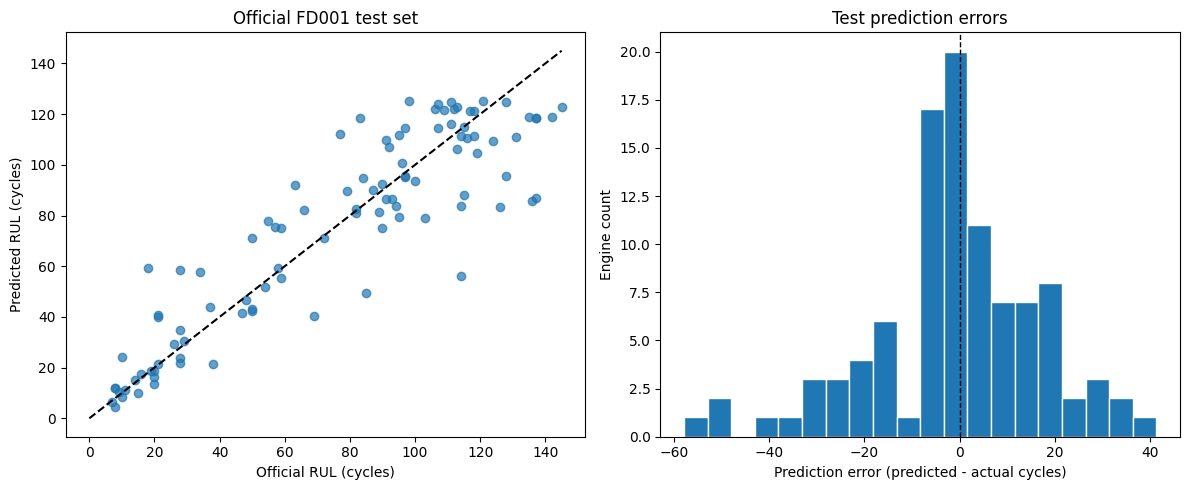

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
limit = max(float(test_actual.max()), float(test_prediction.max()), 1)
axes[0].scatter(test_actual, test_prediction, alpha=0.7)
axes[0].plot([0, limit], [0, limit], '--', color='black')
axes[0].set(xlabel='Official RUL (cycles)', ylabel='Predicted RUL (cycles)', title='Official FD001 test set')
axes[1].hist(test_predictions['error'], bins=20, edgecolor='white')
axes[1].axvline(0, color='black', linestyle='--', linewidth=1)
axes[1].set(xlabel='Prediction error (predicted - actual cycles)', ylabel='Engine count', title='Test prediction errors')
fig.tight_layout()
plt.show()


,feature,mae_increase_when_shuffled
45,sensor_4_mean_5,3.383500
87,sensor_11_mean_5,2.626405
0,cycle,2.594828
46,sensor_4_mean_10,2.009192
34,sensor_2_mean_10,1.889558
40,sensor_3_mean_10,1.810324
47,sensor_4_mean_20,1.308390
112,sensor_15_mean_10,1.210546
93,sensor_12_mean_5,1.041286
33,sensor_2_mean_5,0.945024


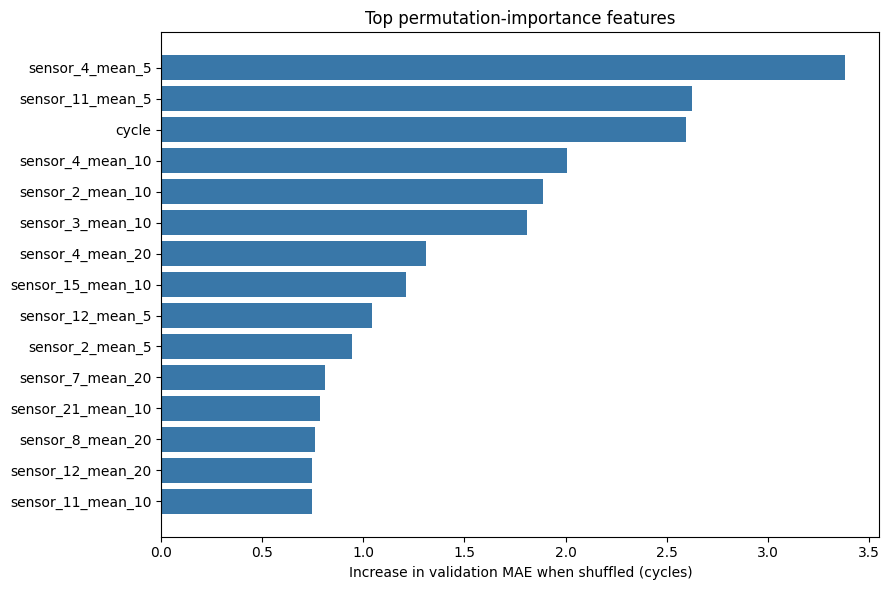

In [40]:

# calculate permutation feature importance
importance = permutation_importance(
    tuned_model,
    x_validation,
    y_validation,
    scoring='neg_mean_absolute_error',
    n_repeats=3,
    random_state=seed
)


# create feature importance dataframe
importance_table = pd.DataFrame({
    'feature': feature_columns,
    'mae_increase_when_shuffled': importance.importances_mean
}).sort_values(
    'mae_increase_when_shuffled',
    ascending=False
)


# display top 15 important features
display(importance_table.head(15))


# prepare data for feature importance visualization
plot_importance = (
    importance_table.head(15)
    .sort_values('mae_increase_when_shuffled')
)


# visualize permutation feature importance
fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    plot_importance.feature,
    plot_importance.mae_increase_when_shuffled,
    color='#3977a8'
)

ax.set(
    xlabel='Increase in validation MAE when shuffled (cycles)',
    title='Top permutation-importance features'
)


# adjust layout and display plot
fig.tight_layout()
plt.show()
